['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8', 'pixel9', 'pixel10', 'pixel11', 'pixel12', 'pixel13', 'pixel14', 'pixel15', 'pixel16', 'pixel17', 'pixel18', 'pixel19', 'pixel20', 'pixel21', 'pixel22', 'pixel23', 'pixel24', 'pixel25', 'pixel26', 'pixel27', 'pixel28', 'pixel29', 'pixel30', 'pixel31', 'pixel32', 'pixel33', 'pixel34', 'pixel35', 'pixel36', 'pixel37', 'pixel38', 'pixel39', 'pixel40', 'pixel41', 'pixel42', 'pixel43', 'pixel44', 'pixel45', 'pixel46', 'pixel47', 'pixel48', 'pixel49', 'pixel50', 'pixel51', 'pixel52', 'pixel53', 'pixel54', 'pixel55', 'pixel56', 'pixel57', 'pixel58', 'pixel59', 'pixel60', 'pixel61', 'pixel62', 'pixel63', 'pixel64', 'pixel65', 'pixel66', 'pixel67', 'pixel68', 'pixel69', 'pixel70', 'pixel71', 'pixel72', 'pixel73', 'pixel74', 'pixel75', 'pixel76', 'pixel77', 'pixel78', 'pixel79', 'pixel80', 'pixel81', 'pixel82', 'pixel83', 'pixel84', 'pixel85', 'pixel86', 'pixel87', 'pixel88', 'pixel89', 'pixel90',

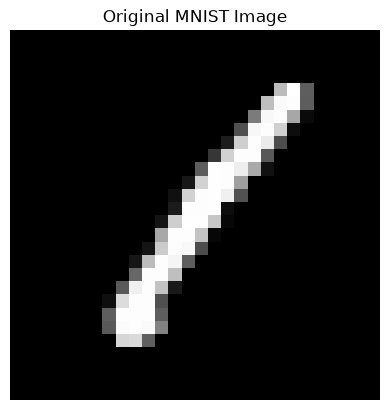

In [5]:
import csv
import numpy as np
import matplotlib.pyplot as plt

with open("train.csv", "r") as file:
    reader = csv.reader(file)
    header = next(reader)
    print(header)
    print(len(header))
    row = next(reader)

# First value is the label; remaining 784 values are pixels
label = int(row[0])
pixels = [float(x) for x in row[1:]]

A = np.array(pixels).reshape(28, 28)

print("Digit label:", label)
print("Image shape:", A.shape)

plt.imshow(A, cmap="gray")
plt.title("Original MNIST Image")
plt.axis("off")
plt.show()

In [17]:
def jacobi_eigen(A, tolerance=1e-10, max_iterations=100000):
    n = len(A)

    # Copy the symmetric matrix
    B = A.astype(float).copy()
    V = np.eye(n)

    for iteration in range(max_iterations):
        # Find the largest off-diagonal element
        p, q = 0, 1
        largest = 0.0

        for i in range(n):
            for j in range(i + 1, n):
                if abs(B[i, j]) > largest:
                    largest = abs(B[i, j])
                    p, q = i, j

        if largest < tolerance:
            break

        # Calculate the Jacobi rotation angle
        tau = (B[q, q] - B[p, p]) / (2.0 * B[p, q])

        if tau >= 0:
            t = 1.0 / (tau + (1.0 + tau * tau) ** 0.5)
        else:
            t = -1.0 / (-tau + (1.0 + tau * tau) ** 0.5)

        c = 1.0 / (1.0 + t * t) ** 0.5
        s = t * c

        app = B[p, p]
        aqq = B[q, q]
        apq = B[p, q]

        B[p, p] = app - t * apq
        B[q, q] = aqq + t * apq
        B[p, q] = 0.0
        B[q, p] = 0.0

        for r in range(n):
            if r != p and r != q:
                arp = B[r, p]
                arq = B[r, q]

                B[r, p] = c * arp - s * arq
                B[p, r] = B[r, p]

                B[r, q] = s * arp + c * arq
                B[q, r] = B[r, q]

        # Update eigenvectors
        for r in range(n):
            vrp = V[r, p]
            vrq = V[r, q]

            V[r, p] = c * vrp - s * vrq
            V[r, q] = s * vrp + c * vrq

    eigenvalues = [B[i, i] for i in range(n)]

    # Sort eigenvalues and eigenvectors in descending order
    indices = sorted(range(n),
                     key=lambda i: eigenvalues[i],
                     reverse=True)

    eigenvalues = np.array([eigenvalues[i] for i in indices])
    V = V[:, indices]

    return eigenvalues, V


def svd_from_scratch(A):
    m, n = A.shape

    # Step 1: Calculate A transpose A
    B = A.T @ A

    # Step 2: Eigenvalues and eigenvectors
    eigenvalues, V = jacobi_eigen(B)

    # Step 3: Singular values
    singular_values = np.array([
        (max(value, 0.0)) ** 0.5
        for value in eigenvalues
    ])

    # Step 4: Calculate U
    U = np.zeros((m, n))

    for j in range(n):
        if singular_values[j] > 1e-10:
            for i in range(m):
                total = 0.0
                for r in range(n):
                    total += A[i, r] * V[r, j]

                U[i, j] = total / singular_values[j]

    return U, singular_values, V.T


U, S, VT = svd_from_scratch(A)

print("U shape:", U.shape)
print("Singular values:", S[:5])
print("VT shape:", VT.shape)

U shape: (28, 28)
Singular values: [1043.46266292  961.30518144  810.97562963  668.78033516  508.68408755]
VT shape: (28, 28)


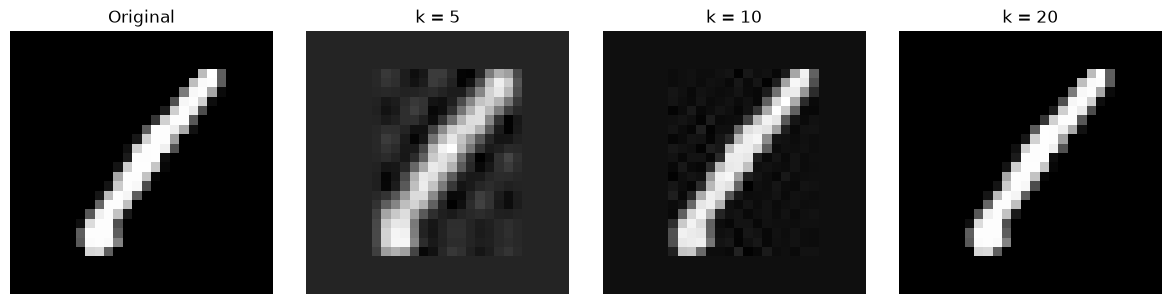

In [18]:
def reconstruct_image(U, S, VT, k):
    m = U.shape[0]
    n = VT.shape[1]

    reconstructed = np.zeros((m, n))

    for r in range(k):
        for i in range(m):
            for j in range(n):
                reconstructed[i, j] += (
                    U[i, r] * S[r] * VT[r, j]
                )

    return reconstructed


k_values = [5, 10, 20]
reconstructed_images = {}

for k in k_values:
    reconstructed_images[k] = reconstruct_image(U, S, VT, k)

# Display original and reconstructed images
plt.figure(figsize=(12, 3))

plt.subplot(1, 4, 1)
plt.imshow(A, cmap="gray")
plt.title("Original")
plt.axis("off")

for index, k in enumerate(k_values, start=2):
    plt.subplot(1, 4, index)
    plt.imshow(reconstructed_images[k], cmap="gray")
    plt.title(f"k = {k}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
def frobenius_error(A, reconstructed):
    total = 0.0

    for i in range(A.shape[0]):
        for j in range(A.shape[1]):
            difference = A[i, j] - reconstructed[i, j]
            total += difference * difference

    return total ** 0.5


errors = {}

for k in k_values:
    errors[k] = frobenius_error(A, reconstructed_images[k])
    print(f"k = {k}, Frobenius error = {errors[k]:.4f}")

k = 5, Frobenius error = 500.6085
k = 10, Frobenius error = 154.5988
k = 20, Frobenius error = 0.0000


In [20]:
m, n = A.shape

original_storage = m * n

for k in k_values:
    compressed_storage = k * (m + n + 1)

    compression_ratio = original_storage / compressed_storage

    print(f"\nk = {k}")
    print("Original values:", original_storage)
    print("Compressed values:", compressed_storage)
    print(f"Compression ratio: {compression_ratio:.2f}:1")


k = 5
Original values: 784
Compressed values: 285
Compression ratio: 2.75:1

k = 10
Original values: 784
Compressed values: 570
Compression ratio: 1.38:1

k = 20
Original values: 784
Compressed values: 1140
Compression ratio: 0.69:1
